# Notebook 04 – Thực nghiệm Dữ liệu lớn: PySpark MLlib vs Scikit-learn

**Nội dung thực hiện:**
1. **Mở rộng quy mô dữ liệu:** Nhân bản dữ liệu sạch ở 4 mức quy mô **x1** (~35K dòng), **x10** (~350K dòng), **x30** (~1.04M dòng), **x60** (~2.09M dòng).
2. **Thực nghiệm công bằng:** Huấn luyện `RandomForestRegressor` với cùng siêu tham số (`numTrees = 50`, `maxDepth = 10`, 9 đặc trưng, `seed = 42`) trên **PySpark MLlib** (`local[*]`) và **pandas + scikit-learn**.
3. **Đo lường hiệu năng:** So sánh và vẽ biểu đồ **Thời gian chạy** (Load, Prep, Train) cùng **Bộ nhớ RAM đỉnh (GB)** giữa Spark và đơn máy.

In [1]:
import os
import sys
import gc
import time
import platform
import subprocess
import threading
import warnings

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psutil
import sklearn
import pyspark
from sklearn.ensemble import RandomForestRegressor
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor as SparkRandomForestRegressor

%matplotlib inline
sns.set_theme(style="whitegrid", font_scale=1.05)

DATA_PATH = "../data/processed/clean_data.parquet"
BENCH_DIR = os.path.join("..", "data", "processed", "benchmark")
RESULTS_DIR = os.path.join("..", "results")
FIG_DIR = os.path.join("..", "figures")
for d in [BENCH_DIR, RESULTS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

# ===== Cấu hình thí nghiệm (khóa chặt ở cả 2 công cụ) =====
BASIC_FEATURES = ["hour", "day_of_week", "month", "is_weekend", "is_rush_hour", "is_holiday",
                  "temp_c", "rain_1h", "clouds_all"]
LABEL = "traffic_volume"
SCALES = [1, 10, 30, 60]
N_TREES = 50
MAX_DEPTH = 10
SEED = 42
N_REPEAT = 3

In [2]:
def lay_ten_cpu():
    # Trên Windows đọc tên CPU từ Registry; hệ điều hành khác dùng platform.processor()
    try:
        import winreg
        khoa = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(khoa, "ProcessorNameString")[0].strip()
    except Exception:
        return platform.processor()


def lay_phien_ban_java():
    try:
        kq = subprocess.run(["java", "-version"], capture_output=True, text=True)
        return (kq.stderr or kq.stdout).splitlines()[0]
    except Exception:
        return "không xác định"


moi_truong = pd.DataFrame({
    "Thông số": ["CPU", "Số lõi vật lý / luồng logic", "RAM tổng (GB)", "Hệ điều hành", "Python", "pandas",
                 "scikit-learn", "PySpark", "Java", "Spark master"],
    "Giá trị": [lay_ten_cpu(), f"{psutil.cpu_count(logical=False)} / {psutil.cpu_count(logical=True)}",
                round(psutil.virtual_memory().total / 1024 ** 3, 2), f"{platform.system()} {platform.release()} ({platform.version()})",
                platform.python_version(), pd.__version__, sklearn.__version__, pyspark.__version__,
                lay_phien_ban_java(), "local[*]"],
})
moi_truong.to_csv(os.path.join(RESULTS_DIR, "benchmark_environment.csv"), index=False, encoding="utf-8-sig")
moi_truong

,Thông số,Giá trị
0,CPU,AMD Ryzen 5 5500U with Radeon Graphics
1,Số lõi vật lý / luồng logic,6 / 12
2,RAM tổng (GB),7.34
3,Hệ điều hành,Windows 11 (10.0.26200)
4,Python,3.14.6
5,pandas,3.0.3
6,scikit-learn,1.9.0
7,PySpark,4.3.0
8,Java,"openjdk version ""17.0.20.1"" 2026-08-18"
9,Spark master,local[*]


In [3]:
base = pd.read_parquet(DATA_PATH, columns=BASIC_FEATURES + [LABEL])
base[LABEL] = base[LABEL].astype(float)
n_base = len(base)
rng = np.random.default_rng(SEED)

duong_dan_theo_quy_mo = {}
for k in SCALES:
    path = os.path.join(BENCH_DIR, f"traffic_x{k}.parquet")
    duong_dan_theo_quy_mo[k] = path
    if os.path.exists(path) and pd.read_parquet(path, columns=["hour"]).shape[0] == n_base * k:
        print(f"x{k}: đã có file, bỏ qua")
        continue
    cac_ban_sao = []
    for i in range(k):
        ban_sao = base.copy()
        if i > 0:   # bản gốc giữ nguyên, các bản sao sau thêm nhiễu
            ban_sao["temp_c"] = ban_sao["temp_c"] + rng.normal(0, 0.5, n_base)
            ban_sao["clouds_all"] = (ban_sao["clouds_all"] + rng.normal(0, 2, n_base)).clip(0, 100)
            co_mua = ban_sao["rain_1h"] > 0
            ban_sao["rain_1h"] = (ban_sao["rain_1h"] + co_mua * np.abs(rng.normal(0, 0.05, n_base))).clip(lower=0)
            ban_sao[LABEL] = (ban_sao[LABEL] + rng.normal(0, 30, n_base)).clip(lower=0)
        cac_ban_sao.append(ban_sao)
    big = pd.concat(cac_ban_sao, ignore_index=True)
    big["clouds_all"] = big["clouds_all"].astype(float)
    big.to_parquet(path, index=False, row_group_size=50_000)
    print(f"x{k}: {len(big):,} dòng -> {path}")
    del big, cac_ban_sao
    gc.collect()

bang_quy_mo = pd.DataFrame({
    "Quy mô": [f"x{k}" for k in SCALES],
    "Số dòng": [n_base * k for k in SCALES],
    "Dung lượng file (MB)": [round(os.path.getsize(duong_dan_theo_quy_mo[k]) / 1024 ** 2, 2) for k in SCALES],
})
bang_quy_mo

x1: đã có file, bỏ qua
x10: đã có file, bỏ qua
x30: đã có file, bỏ qua
x60: đã có file, bỏ qua


,Quy mô,Số dòng,Dung lượng file (MB)
0,x1,34833,0.19
1,x10,348330,9.10
2,x30,1044990,28.88
3,x60,2089980,58.56


In [4]:
def ram_python_gb():
    # RSS (bộ nhớ vật lý đang dùng) của tiến trình Python hiện tại
    return psutil.Process(os.getpid()).memory_info().rss / 1024 ** 3


def ram_spark_jvm_gb():
    # Tổng RSS của các tiến trình con tên 'java' (JVM của Spark)
    tong = 0
    for p in psutil.Process(os.getpid()).children(recursive=True):
        try:
            if "java" in p.name().lower():
                tong += p.memory_info().rss
        except (psutil.NoSuchProcess, psutil.AccessDenied):
            pass
    return tong / 1024 ** 3


def chay_va_do_ram_dinh(ham_can_chay, ham_do_ram, duong_dan):
    # Chạy ham_can_chay(duong_dan); song song đó luồng phụ đo RAM mỗi 0.1s để lấy giá trị lớn nhất
    ram_dinh = [ham_do_ram()]
    dang_chay = [True]

    def lay_mau_ram():
        while dang_chay[0]:
            ram_dinh[0] = max(ram_dinh[0], ham_do_ram())
            time.sleep(0.1)

    luong_phu = threading.Thread(target=lay_mau_ram)
    luong_phu.start()
    try:
        ket_qua = ham_can_chay(duong_dan)
    finally:
        dang_chay[0] = False
        luong_phu.join()
    ket_qua["ram_gb"] = max(ram_dinh[0], ham_do_ram())
    return ket_qua

In [5]:
def chay_pandas_sklearn(duong_dan):
    gc.collect()
    tg = {}

    t0 = time.perf_counter()
    pdf = pd.read_parquet(duong_dan)                                   # (1) Load
    tg["load_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    X = pdf[BASIC_FEATURES].to_numpy(dtype=np.float32)                 # (2) Prep
    y = pdf[LABEL].to_numpy(dtype=np.float64)
    tg["prep_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    rf = RandomForestRegressor(n_estimators=N_TREES, max_depth=MAX_DEPTH, max_features=3,   # 3 = 1/3 của 9 đặc trưng
                               random_state=SEED, n_jobs=-1)
    rf.fit(X, y)                                                       # (3) Train
    tg["train_s"] = time.perf_counter() - t0

    tg["n_rows"] = len(pdf)
    del pdf, X, y, rf
    gc.collect()
    return tg

In [6]:
t0 = time.perf_counter()
spark = (SparkSession.builder
         .master("local[*]")
         .appName("BDA_Traffic_Benchmark")
         .config("spark.driver.memory", "3g")
         .config("spark.sql.shuffle.partitions", str(psutil.cpu_count(logical=True)))
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print(f"Khởi động Spark {spark.version} mất {time.perf_counter() - t0:.1f}s (không tính vào benchmark)")
print("defaultParallelism:", spark.sparkContext.defaultParallelism)


def chay_spark(duong_dan):
    spark.catalog.clearCache()
    duong_dan_spark = os.path.abspath(duong_dan).replace("\\", "/")   # Spark trên Windows dùng dấu '/'
    tg = {}

    t0 = time.perf_counter()
    sdf = spark.read.parquet(duong_dan_spark).cache()                  # (1) Load
    n_rows = sdf.count()                                               # action -> ép đọc dữ liệu thật
    tg["load_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    assembler = VectorAssembler(inputCols=BASIC_FEATURES, outputCol="features")
    sdf_prep = (assembler.transform(sdf)                               # (2) Prep
                .select("features", F.col(LABEL).cast("double").alias("label"))
                .cache())
    sdf_prep.count()                                                   # action -> ép thực thi VectorAssembler
    sdf.unpersist()
    tg["prep_s"] = time.perf_counter() - t0

    t0 = time.perf_counter()
    rf = SparkRandomForestRegressor(featuresCol="features", labelCol="label", numTrees=N_TREES,
                                    maxDepth=MAX_DEPTH, seed=SEED, featureSubsetStrategy="onethird")
    model = rf.fit(sdf_prep)                                           # (3) Train
    tg["train_s"] = time.perf_counter() - t0

    tg["n_rows"] = n_rows
    tg["so_partition"] = sdf_prep.rdd.getNumPartitions()
    sdf_prep.unpersist()
    del model
    return tg

Khởi động Spark 4.3.0 mất 26.3s (không tính vào benchmark)
defaultParallelism: 12


In [7]:
t0 = time.perf_counter()
_ = chay_spark(duong_dan_theo_quy_mo[1])
_ = chay_pandas_sklearn(duong_dan_theo_quy_mo[1])
print(f"Warm-up xong trong {time.perf_counter() - t0:.1f}s (kết quả bị bỏ qua)")

Warm-up xong trong 37.3s (kết quả bị bỏ qua)


In [8]:
cac_lan_do = []
t_bat_dau = time.perf_counter()
for k in SCALES:
    for cong_cu, ham_chay, ham_ram in [("PySpark MLlib", chay_spark, ram_spark_jvm_gb),
                                       ("pandas/scikit-learn", chay_pandas_sklearn, ram_python_gb)]:
        for lan in range(1, N_REPEAT + 1):
            kq = chay_va_do_ram_dinh(ham_chay, ham_ram, duong_dan_theo_quy_mo[k])
            kq.update({"engine": cong_cu, "scale": f"x{k}", "repeat": lan})
            kq["total_s"] = kq["load_s"] + kq["prep_s"] + kq["train_s"]
            cac_lan_do.append(kq)
            print(f"x{k:<3}| {cong_cu:<20}| lần {lan} | load {kq['load_s']:6.2f}s | prep {kq['prep_s']:6.2f}s | "
                  f"train {kq['train_s']:7.2f}s | tổng {kq['total_s']:7.2f}s | RAM đỉnh {kq['ram_gb']:.2f} GB")
print(f"\nTổng thời gian chạy benchmark: {(time.perf_counter() - t_bat_dau) / 60:.1f} phút")

raw_df = pd.DataFrame(cac_lan_do)
raw_df.to_csv(os.path.join(RESULTS_DIR, "benchmark_raw_runs.csv"), index=False, encoding="utf-8-sig")

x1  | PySpark MLlib       | lần 1 | load   0.80s | prep   1.37s | train   14.30s | tổng   16.47s | RAM đỉnh 1.11 GB
x1  | PySpark MLlib       | lần 2 | load   0.40s | prep   0.50s | train   14.03s | tổng   14.92s | RAM đỉnh 1.14 GB
x1  | PySpark MLlib       | lần 3 | load   0.42s | prep   0.43s | train   16.44s | tổng   17.29s | RAM đỉnh 1.29 GB
x1  | pandas/scikit-learn | lần 1 | load   0.01s | prep   0.01s | train    0.39s | tổng    0.41s | RAM đỉnh 0.26 GB
x1  | pandas/scikit-learn | lần 2 | load   0.02s | prep   0.01s | train    0.87s | tổng    0.90s | RAM đỉnh 0.26 GB
x1  | pandas/scikit-learn | lần 3 | load   0.01s | prep   0.00s | train    0.37s | tổng    0.38s | RAM đỉnh 0.25 GB
x10 | PySpark MLlib       | lần 1 | load   1.01s | prep   1.45s | train   44.04s | tổng   46.50s | RAM đỉnh 1.70 GB
x10 | PySpark MLlib       | lần 2 | load   0.62s | prep   0.98s | train   38.81s | tổng   40.41s | RAM đỉnh 2.04 GB
x10 | PySpark MLlib       | lần 3 | load   0.64s | prep   1.18s | train 

In [9]:
benchmark = (raw_df.groupby(["engine", "scale"], sort=False)
             .agg(n_rows=("n_rows", "first"), load_s=("load_s", "mean"), prep_s=("prep_s", "mean"),
                  train_s=("train_s", "mean"), total_s=("total_s", "mean"), total_std_s=("total_s", "std"),
                  ram_peak_gb=("ram_gb", "max"))
             .reset_index())
benchmark["throughput_rows_per_s"] = benchmark["n_rows"] / benchmark["total_s"]
benchmark = benchmark.round(3)
benchmark.to_csv(os.path.join(RESULTS_DIR, "benchmark.csv"), index=False, encoding="utf-8-sig")
benchmark

,engine,scale,n_rows,load_s,prep_s,train_s,total_s,total_std_s,ram_peak_gb,throughput_rows_per_s
0,PySpark MLlib,x1,34833,0.539,0.767,14.924,16.230,1.205,1.286,2146.230
1,pandas/scikit-learn,x1,34833,0.013,0.005,0.545,0.563,0.291,0.265,61838.613
2,PySpark MLlib,x10,348330,0.758,1.203,44.739,46.700,6.390,2.255,7458.897
3,pandas/scikit-learn,x10,348330,0.114,0.026,9.336,9.476,2.040,0.354,36758.832
4,PySpark MLlib,x30,1044990,1.461,2.386,65.795,69.642,8.291,2.522,15005.213
5,pandas/scikit-learn,x30,1044990,0.220,0.036,25.132,25.387,0.832,0.638,41162.071
6,PySpark MLlib,x60,2089980,1.689,3.866,100.984,106.540,11.126,3.240,19616.932
7,pandas/scikit-learn,x60,2089980,0.632,0.125,75.501,76.259,4.711,1.061,27406.383


In [10]:
# Tỷ lệ thời gian: > 1 nghĩa là Spark nhanh hơn pandas/sklearn
so_sanh = benchmark.pivot(index="scale", columns="engine", values="total_s").reindex([f"x{k}" for k in SCALES])
so_sanh["Tỷ lệ pandas/Spark"] = so_sanh["pandas/scikit-learn"] / so_sanh["PySpark MLlib"]
ram = benchmark.pivot(index="scale", columns="engine", values="ram_peak_gb").reindex([f"x{k}" for k in SCALES])
so_sanh["RAM Spark JVM (GB)"] = ram["PySpark MLlib"]
so_sanh["RAM Python (GB)"] = ram["pandas/scikit-learn"]
so_sanh.insert(0, "Số dòng", [n_base * k for k in SCALES])
so_sanh.round(2)

engine,Số dòng,PySpark MLlib,pandas/scikit-learn,Tỷ lệ pandas/Spark,RAM Spark JVM (GB),RAM Python (GB)
scale,,,,,,
x1,34833,16.23,0.56,0.03,1.29,0.26
x10,348330,46.70,9.48,0.20,2.26,0.35
x30,1044990,69.64,25.39,0.36,2.52,0.64
x60,2089980,106.54,76.26,0.72,3.24,1.06


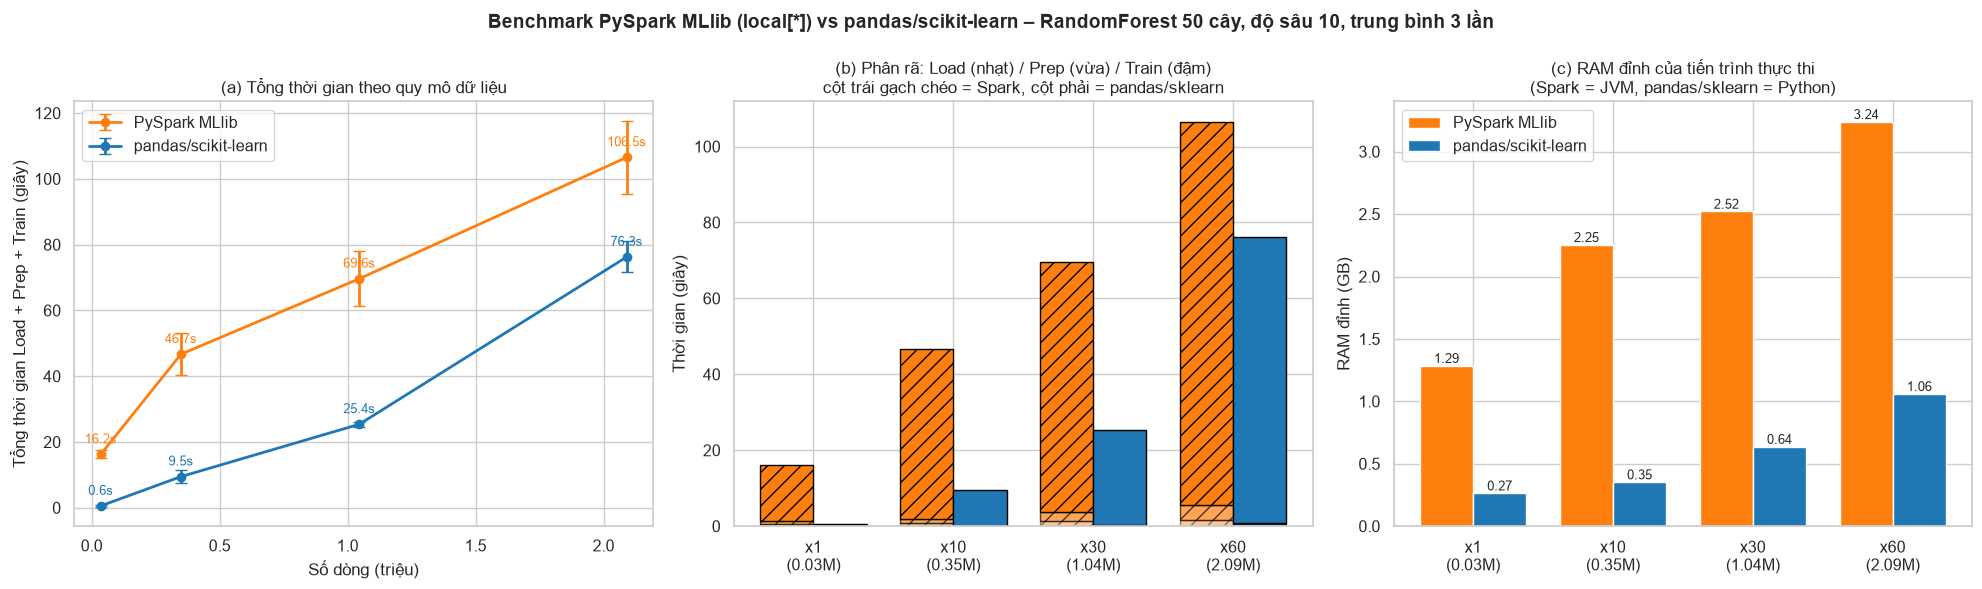

In [11]:
mau = {"PySpark MLlib": "tab:orange", "pandas/scikit-learn": "tab:blue"}
nhan_quy_mo = [f"x{k}\n({n_base * k / 1e6:.2f}M)" for k in SCALES]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# (a) Tổng thời gian theo số dòng
for cong_cu in mau:
    d = benchmark[benchmark["engine"] == cong_cu]
    axes[0].errorbar(d["n_rows"] / 1e6, d["total_s"], yerr=d["total_std_s"], marker="o", capsize=4,
                     linewidth=2, color=mau[cong_cu], label=cong_cu)
    for x, y in zip(d["n_rows"] / 1e6, d["total_s"]):
        axes[0].annotate(f"{y:.1f}s", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, color=mau[cong_cu])
axes[0].set_xlabel("Số dòng (triệu)")
axes[0].set_ylabel("Tổng thời gian Load + Prep + Train (giây)")
axes[0].set_title("(a) Tổng thời gian theo quy mô dữ liệu")
axes[0].legend()

# (b) Phân rã thời gian 3 giai đoạn (cột chồng) – mỗi quy mô 2 cột: Spark (trái), pandas (phải)
vi_tri = np.arange(len(SCALES))
rong = 0.38
for j, cong_cu in enumerate(mau):
    d = benchmark[benchmark["engine"] == cong_cu].set_index("scale").reindex([f"x{k}" for k in SCALES])
    x = vi_tri + (j - 0.5) * rong
    axes[1].bar(x, d["load_s"], rong, color=mau[cong_cu], alpha=0.45, edgecolor="black", hatch="//" if j == 0 else "")
    axes[1].bar(x, d["prep_s"], rong, bottom=d["load_s"], color=mau[cong_cu], alpha=0.7, edgecolor="black", hatch="//" if j == 0 else "")
    axes[1].bar(x, d["train_s"], rong, bottom=d["load_s"] + d["prep_s"], color=mau[cong_cu], alpha=1.0, edgecolor="black", hatch="//" if j == 0 else "")
axes[1].set_xticks(vi_tri)
axes[1].set_xticklabels(nhan_quy_mo)
axes[1].set_ylabel("Thời gian (giây)")
axes[1].set_title("(b) Phân rã: Load (nhạt) / Prep (vừa) / Train (đậm)\ncột trái gạch chéo = Spark, cột phải = pandas/sklearn")

# (c) RAM đỉnh
for j, cong_cu in enumerate(mau):
    d = benchmark[benchmark["engine"] == cong_cu].set_index("scale").reindex([f"x{k}" for k in SCALES])
    x = vi_tri + (j - 0.5) * rong
    axes[2].bar(x, d["ram_peak_gb"], rong, color=mau[cong_cu], label=cong_cu)
    for xi, v in zip(x, d["ram_peak_gb"]):
        axes[2].text(xi, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
axes[2].set_xticks(vi_tri)
axes[2].set_xticklabels(nhan_quy_mo)
axes[2].set_ylabel("RAM đỉnh (GB)")
axes[2].set_title("(c) RAM đỉnh của tiến trình thực thi\n(Spark = JVM, pandas/sklearn = Python)")
axes[2].legend()

fig.suptitle(f"Benchmark PySpark MLlib (local[*]) vs pandas/scikit-learn – RandomForest {N_TREES} cây, độ sâu {MAX_DEPTH}, "
             f"trung bình {N_REPEAT} lần", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_res_benchmark.png"), dpi=200, bbox_inches="tight")
plt.show()

In [12]:
# Nhận xét tự động từ số liệu
print("NHẬN XÉT BENCHMARK")
for k in SCALES:
    r = so_sanh.loc[f"x{k}"]
    nhanh_hon = "Spark nhanh hơn" if r["Tỷ lệ pandas/Spark"] > 1 else "pandas/sklearn nhanh hơn"
    print(f"- x{k:<3} ({int(r['Số dòng']):>9,} dòng): Spark {r['PySpark MLlib']:7.2f}s | pandas/sklearn {r['pandas/scikit-learn']:7.2f}s "
          f"-> {nhanh_hon} ({max(r['Tỷ lệ pandas/Spark'], 1 / r['Tỷ lệ pandas/Spark']):.2f} lần)")
d_sp = benchmark[benchmark["engine"] == "PySpark MLlib"].set_index("scale")
d_pd = benchmark[benchmark["engine"] == "pandas/scikit-learn"].set_index("scale")
print(f"- Khi dữ liệu tăng 60 lần: thời gian Spark tăng {d_sp.loc['x60', 'total_s'] / d_sp.loc['x1', 'total_s']:.1f} lần, "
      f"pandas/sklearn tăng {d_pd.loc['x60', 'total_s'] / d_pd.loc['x1', 'total_s']:.1f} lần.")
print(f"- RAM đỉnh ở x60: Spark JVM {d_sp.loc['x60', 'ram_peak_gb']:.2f} GB, Python {d_pd.loc['x60', 'ram_peak_gb']:.2f} GB.")

NHẬN XÉT BENCHMARK
- x1   (   34,833 dòng): Spark   16.23s | pandas/sklearn    0.56s -> pandas/sklearn nhanh hơn (28.83 lần)
- x10  (  348,330 dòng): Spark   46.70s | pandas/sklearn    9.48s -> pandas/sklearn nhanh hơn (4.93 lần)
- x30  (1,044,990 dòng): Spark   69.64s | pandas/sklearn   25.39s -> pandas/sklearn nhanh hơn (2.74 lần)
- x60  (2,089,980 dòng): Spark  106.54s | pandas/sklearn   76.26s -> pandas/sklearn nhanh hơn (1.40 lần)
- Khi dữ liệu tăng 60 lần: thời gian Spark tăng 6.6 lần, pandas/sklearn tăng 135.5 lần.
- RAM đỉnh ở x60: Spark JVM 3.24 GB, Python 1.06 GB.


## . Thảo luận

**Những điểm cần lưu ý khi diễn giải kết quả:**
1. **Chi phí cố định (overhead) của Spark:** mỗi tác vụ Spark phải lập kế hoạch (DAG), chia task, tuần tự hóa dữ liệu giữa JVM… → với dữ liệu nhỏ (x1), Spark thường **chậm hơn** pandas/sklearn dù cùng dùng mọi lõi CPU.
2. **Khả năng mở rộng (scalability):** khi dữ liệu tăng, chi phí cố định được "chia đều" trên nhiều dòng hơn; Spark xử lý song song theo partition và dùng **histogram (maxBins = 32)** khi tìm điểm chia → tốc độ tăng thời gian theo dữ liệu thường chậm hơn.
3. **Bộ nhớ:** JVM của Spark có mức RAM nền cao (cấp phát heap trước), nhưng Spark có thể **tràn xuống đĩa (spill)** và **mở rộng ra cụm nhiều máy** khi dữ liệu vượt RAM một máy – điều pandas/sklearn không làm được (pandas bắt buộc toàn bộ dữ liệu nằm trong RAM).
4. **Giới hạn thí nghiệm:** chạy trên **1 máy** (`local[*]`), dữ liệu tối đa ~2 triệu dòng vẫn vừa RAM → chưa thể hiện hết sức mạnh của Spark trên cụm phân tán. Hai thư viện cũng khác nhau về thuật toán chi tiết (sklearn tìm điểm chia chính xác, Spark dùng histogram), nên kết quả chỉ so sánh **hiệu năng hệ thống**, không so sánh độ chính xác.

**Kết luận:** Với quy mô dữ liệu của đề tài (~35 nghìn dòng), pandas/scikit-learn là lựa chọn hợp lý và đơn giản. Khi dữ liệu tăng lên hàng triệu – hàng tỷ dòng (ví dụ dữ liệu từ hàng nghìn trạm đo giao thông của cả thành phố), PySpark là lựa chọn phù hợp nhờ khả năng mở rộng ngang.